# Clase 6: Comparación de modelos supervisados

## Wall-Following Robot Navigation

En esta práctica se comparan tres algoritmos de clasificación
supervisada: Random Forest, K-Nearest Neighbors (KNN) y
Support Vector Machine (SVM).

La evaluación utiliza Accuracy y F1-score ponderado para
determinar el rendimiento de cada modelo sobre el conjunto
de prueba.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los resultados obtenidos
df_resultados = pd.read_csv(
    "../data/processed/comparacion_modelos.csv"
)

# Mostrar tabla comparativa
display(df_resultados)

,Modelo,Accuracy,F1-score
0,Random Forest,0.992674,0.992689
1,KNN,0.879121,0.878910
2,SVM,0.869048,0.868371


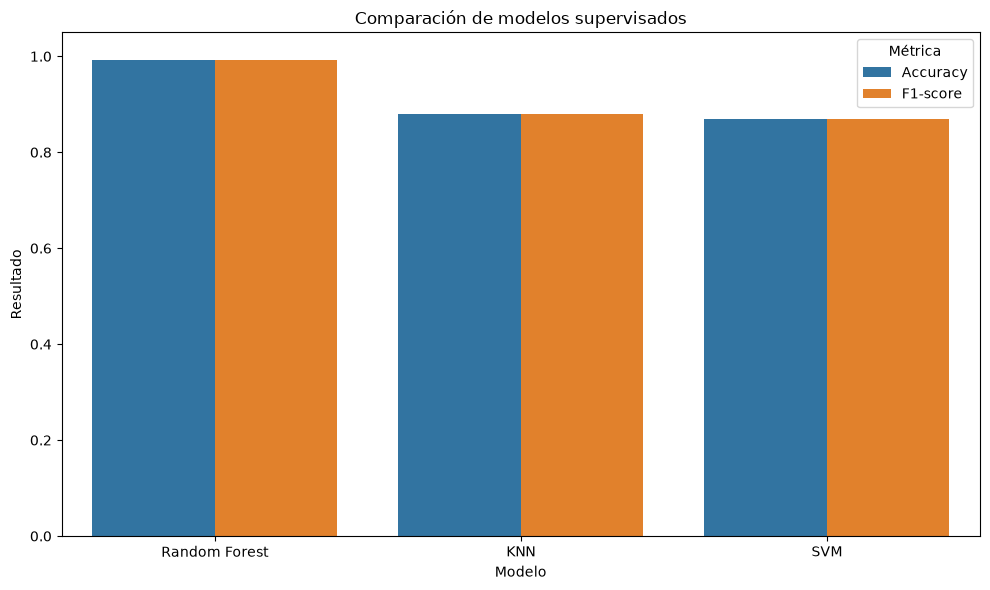

In [2]:
# Preparar resultados para la visualización
datos_grafica = df_resultados.melt(
    id_vars="Modelo",
    value_vars=["Accuracy", "F1-score"],
    var_name="Metrica",
    value_name="Valor"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=datos_grafica,
    x="Modelo",
    y="Valor",
    hue="Metrica"
)

plt.title("Comparación de modelos supervisados")
plt.xlabel("Modelo")
plt.ylabel("Resultado")
plt.ylim(0, 1.05)
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    df_resultados["Modelo"],
    df_resultados["Tiempo (s)"]
)

plt.title("Tiempo de entrenamiento por modelo")
plt.xlabel("Modelo")
plt.ylabel("Tiempo (segundos)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Análisis de resultados

Random Forest obtuvo el mayor rendimiento entre los tres
modelos evaluados, alcanzando un Accuracy de 99,27 % y
un F1-score ponderado de 99,27 %.

KNN alcanzó un Accuracy de 87,91 % y un F1-score de
87,89 %, mientras que SVM obtuvo un Accuracy de 86,90 %
y un F1-score de 86,84 %.

Estos resultados indican que Random Forest presentó una
mayor capacidad de clasificación sobre el conjunto de
prueba utilizado.

No obstante, los resultados corresponden a una única
división de entrenamiento y prueba. Se recomienda
complementar la interpretación con las matrices de
confusión y comprobar posibles duplicados entre conjuntos.

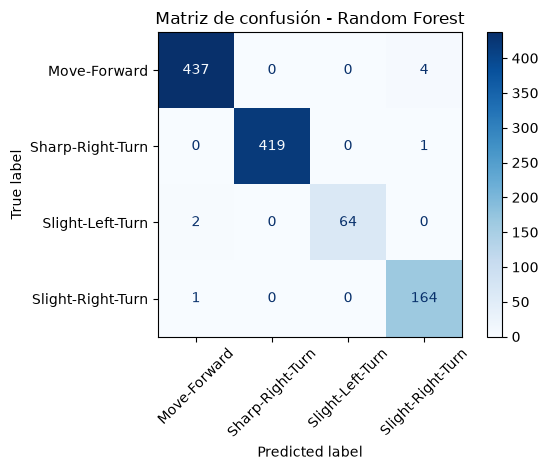

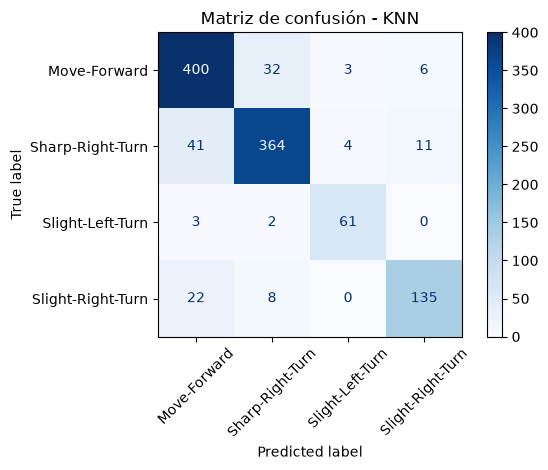

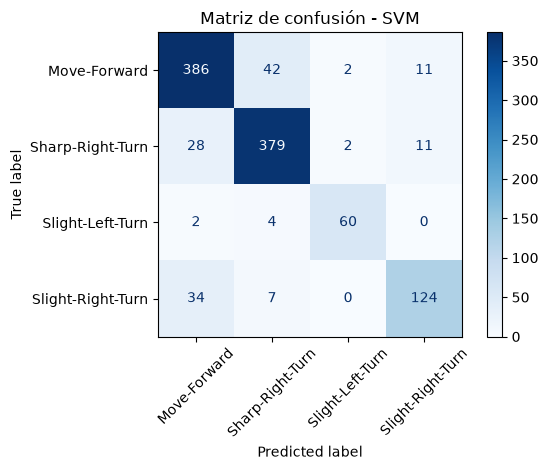

In [3]:
import sys
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

# Acceder a los scripts de la carpeta src
BASE_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(BASE_DIR / "src"))

from data_loader import load_raw_data, preprocess, split_data
from train_supervised import train_random_forest, train_knn, train_svm

# Preparar los mismos datos utilizados en el entrenamiento
df = load_raw_data(BASE_DIR / "data" / "raw" / "sensor_readings_24.data")
X, y = preprocess(df)
X_train, X_test, y_train, y_test, scaler = split_data(X, y)

# Entrenar los tres modelos
modelos = {
    "Random Forest": train_random_forest(X_train, y_train),
    "KNN": train_knn(X_train, y_train),
    "SVM": train_svm(X_train, y_train)
}

# Mostrar una matriz de confusión para cada modelo
for nombre, modelo in modelos.items():
    ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_test,
        y_test,
        cmap="Blues",
        xticks_rotation=45
    )

    plt.title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()


## Conclusión de la Clase 6

Durante esta práctica se implementaron y evaluaron tres algoritmos de aprendizaje supervisado: Random Forest, K-Nearest Neighbors (KNN) y Support Vector Machine (SVM), utilizando el conjunto de datos Wall-Following Robot Navigation.

Los modelos fueron entrenados y evaluados mediante la misma división de datos, empleando Accuracy, F1-score ponderado y matrices de confusión como métricas de evaluación.

Random Forest obtuvo el mejor rendimiento, con un Accuracy de 99,27 % y un F1-score de 99,27 %. Por su parte, KNN alcanzó un Accuracy de 87,91 %, mientras que SVM obtuvo un 86,90 %.

Los resultados evidencian que Random Forest fue el modelo más efectivo para clasificar las acciones de navegación del robot en el conjunto de prueba utilizado.

Las matrices de confusión permitieron visualizar los aciertos y errores de clasificación de cada algoritmo. No obstante, sería conveniente realizar una validación cruzada y revisar posibles registros duplicados para comprobar la estabilidad de los resultados.

En conclusión, Random Forest se identifica como el modelo más prometedor de los tres evaluados para este problema de clasificación supervisada.


### Comparación de tiempos de entrenamiento

Se midió el tiempo de entrenamiento de los algoritmos Random Forest, KNN y SVM mediante la función `perf_counter()` de Python.

Los resultados permiten comparar el costo temporal del entrenamiento de cada algoritmo bajo las mismas condiciones de ejecución.

La evaluación conjunta de Accuracy, F1-score y tiempo de entrenamiento permite identificar las ventajas y limitaciones de cada modelo. Random Forest obtuvo el mayor rendimiento predictivo, con un Accuracy del 99,27 % y un F1-score ponderado del 99,27 %.

No obstante, la selección del modelo más adecuado también debe considerar el tiempo de entrenamiento y los requisitos de la aplicación robótica. Estos tiempos no representan necesariamente la velocidad de predicción, que se evaluará posteriormente mediante pruebas de latencia.

TABLA COMPARATIVA DE MODELOS SUPERVISADOS


,Modelo,Accuracy (%),F1-score (%),Tiempo (s),Tiempo (ms)
0,Random Forest,99.27,99.27,0.3920,392.05
1,KNN,87.91,87.89,0.0103,10.29
2,SVM,86.90,86.84,0.6928,692.83


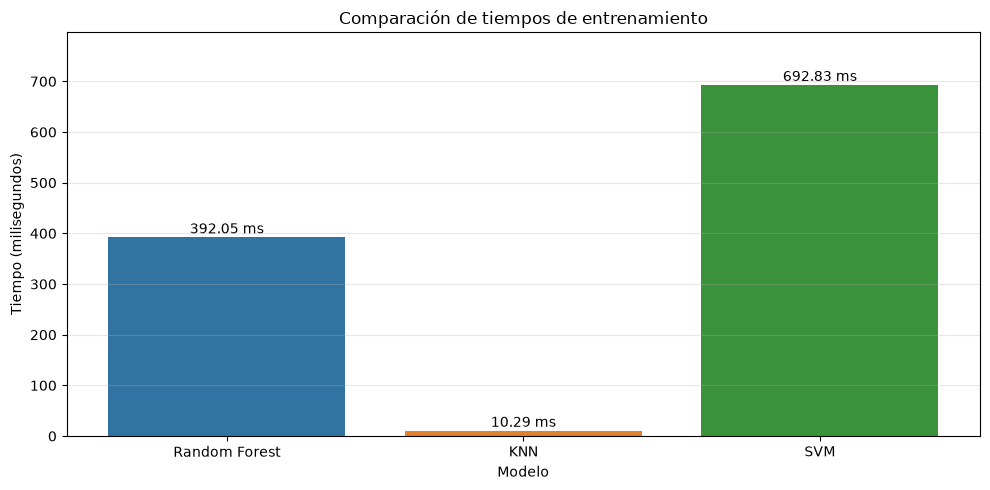

Modelo con menor tiempo de entrenamiento: KNN
Modelo con mayor Accuracy: Random Forest


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar resultados reales del proyecto
df = pd.read_csv("../data/processed/comparacion_modelos.csv")

# Crear tabla comparativa
tabla = df[["Modelo", "Accuracy", "F1-score", "Tiempo (s)"]].copy()

tabla["Accuracy (%)"] = (tabla["Accuracy"] * 100).round(2)
tabla["F1-score (%)"] = (tabla["F1-score"] * 100).round(2)
tabla["Tiempo (ms)"] = (tabla["Tiempo (s)"] * 1000).round(2)

tabla = tabla[
    ["Modelo", "Accuracy (%)", "F1-score (%)", "Tiempo (s)", "Tiempo (ms)"]
]

tabla["Tiempo (s)"] = tabla["Tiempo (s)"].round(4)

print("TABLA COMPARATIVA DE MODELOS SUPERVISADOS")
display(tabla)

# Grafica comparativa de tiempos
plt.figure(figsize=(10, 5))

barras = plt.bar(
    tabla["Modelo"],
    tabla["Tiempo (ms)"],
    color=["#3274A1", "#E1812C", "#3A923A"]
)

plt.title("Comparación de tiempos de entrenamiento")
plt.ylabel("Tiempo (milisegundos)")
plt.xlabel("Modelo")

for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 8,
        f"{altura:.2f} ms",
        ha="center"
    )

plt.ylim(0, tabla["Tiempo (ms)"].max() * 1.15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Identificar los mejores resultados
mas_rapido = tabla.loc[tabla["Tiempo (ms)"].idxmin()]
mas_preciso = tabla.loc[tabla["Accuracy (%)"].idxmax()]

print("Modelo con menor tiempo de entrenamiento:", mas_rapido["Modelo"])
print("Modelo con mayor Accuracy:", mas_preciso["Modelo"])

### Análisis comparativo de rendimiento y tiempo

Los resultados muestran que KNN presentó el menor tiempo de entrenamiento, con 10,29 milisegundos, seguido de Random Forest con 392,05 milisegundos y SVM con 692,83 milisegundos.

Sin embargo, Random Forest obtuvo el mejor rendimiento predictivo, alcanzando un Accuracy del 99,27 % y un F1-score ponderado del 99,27 %.

Por tanto, en esta evaluación, KNN destacó por su rapidez de entrenamiento, mientras que Random Forest ofreció el mejor desempeño de clasificación. Los tiempos corresponden a una ejecución específica y no representan la latencia de predicción de los modelos.